In [1]:
import sys, json, re, glob, pathlib, collections
FT = pathlib.Path("/Users/geboou/Desktop/oversight/finetune")
sys.path.insert(0, str(FT/"entregable")); sys.path.insert(0, str(FT/"data_synth/pipeline"))
import evaluation as ev
import design_helpers as dz
from design_helpers import PAL, display, HTML, plt, np
import pandas as pd
V2 = FT/"v2"; RES = V2/"results"
sys.path.insert(0, str(V2)); import gate
dz.setup()
dz.hero("Fine-tuning runs (v2)", "Where the fine-tuning lives: data, anti-shortcut gate, three training arms and an honest side-by-side",
        "goal -> data -> gate -> runs -> comparison -> limits -> reproduce")

**How to read this notebook.** It is the fine-tuning notebook: it shows the v2 fine-tuning end to end. Everything is computed from files on disk (`v2/out`, `v2/sft`, `v2/results`, `v2/gate.py`); nothing is typed in by hand. Runs that have not finished show a *pending* card and fill in automatically when their result files appear. The story of the engine and of v1 is in `01_FINAL_full_story` and `02_deterministic_engine`.

In [2]:
dz.banner(1, 'Goal and honest claim', 'What is the model for, and what are we allowed to say about it?')

In [3]:
dz.cards([("Role","Second-line pattern reviewer","Reads one employee's month of receipts that the deterministic engine already passed, and looks for patterns ACROSS receipts: limit splitting, double claims, items that do not fit the trip, hidden personal spending.",PAL["ft"]),
("Allowed action","Escalate pass -> review only","It can only hand receipts to a human. It never rejects and never lowers a verdict. The engine keeps the verdict.",PAL["good"]),
("Design stance","Bounded AI","The model proposes, code disposes. The design is our own reasoning about where an LLM adds value; it is not copied from any company's product.",PAL["ai"])])
dz.callout("good","<b>Claim we make:</b> a small open model, fine-tuned on engine-validated synthetic histories, can be trained to flag cross-receipt patterns as a second reader, at the cost of a measurable false-alarm rate. <b>Claim we do not make:</b> that it beats frontier models, or that it is validated on independent data (see section 6).")

In [4]:
dz.banner(2, 'The data: v2 pipeline', 'How were the training histories made, and who wrote them?')

v2 fixes the main v1 problem (a single author with a recognisable style). Each history starts from a **code-controlled skeleton** (class, month, persona, entity, country, language, size), so label balance and surface statistics are set by code, not by the author. Then **several model families write the narrative and the planted scheme**: Claude agents, DeepSeek and Kimi. Finally the **deterministic engine validates** every history (each receipt must pass on its own, so the only signal left is the cross-receipt pattern).

In [5]:
FAM = {"claude_clF":"Claude agents","claude_clF2":"Claude agents","claude_clC":"Claude agents","claude_clC2":"Claude agents"}
rows=[]; H=[]
for f in sorted(glob.glob(str(V2/"out"/"*.json"))):
    d=json.load(open(f)); n=pathlib.Path(f).stem
    fam = FAM.get(n) or ("DeepSeek" if n.startswith("deepseek") else "Kimi" if n.startswith("kimi") else n)
    for h in d: h["_fam"]=fam; h["_file"]=n
    H+=d; rows.append((fam,n,sum(h["class"]=="fraud" for h in d),sum(h["class"]=="clean" for h in d),len(d)))
df=pd.DataFrame(rows,columns=["family","file","fraud","clean","total"])
fam_tbl=df.groupby("family")[["fraud","clean","total"]].sum()
fam_tbl.loc["TOTAL"]=fam_tbl.sum()
display(fam_tbl)
split=json.load(open(V2/"sft"/"split.json"))
def nlines(p): return sum(1 for _ in open(p))
ntr=nlines(V2/"sft"/"train.jsonl"); nva=nlines(V2/"sft"/"valid.jsonl")
dz.kpis([(f"{ntr+nva}","SFT histories","big set (Modal arms)",PAL["ft"]),(f"{ntr}","train","",PAL["good"]),(f"{nva}","valid","held-out schemes + clean",PAL["haiku"]),
         (f"{len(split['heldout_schemes'])}","held-out schemes","never seen in training",PAL["ai"]),(f"{len(split['heldout_clean'])}","held-out clean","",PAL["muted"])])
dz.callout("warn","Files with 0 histories are generation batches that returned nothing usable (validated out by the engine or still pending); they are listed above on purpose. The SFT set only uses the batches that survived.")

,fraud,clean,total
family,,,
Claude agents,135,127,262
DeepSeek,27,0,27
Kimi,0,1,1
TOTAL,162,128,290


In [6]:
dz.banner(3, 'The anti-shortcut gate', 'Can surface features alone (no meaning) predict the label? Target AUROC <= 0.60')

The gate (`v2/gate.py`) trains a logistic regression on **surface features only** (weekend share, amounts, round amounts, merchant repetition, text length, category shares...) with 5-fold CV. If that reaches AUROC above 0.60, the dataset has a shortcut: a model could score well without reading the pattern. Numbers below are recomputed now by calling the gate functions.

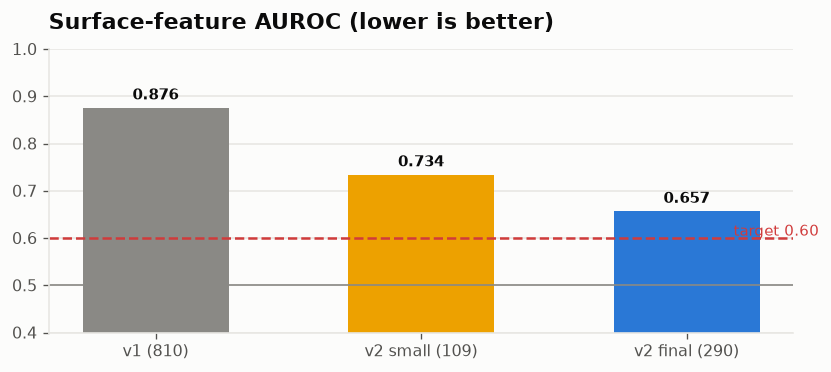

In [7]:
def load_sft(p):
    T=[];Y=[]
    for l in open(p):
        x=json.loads(l); T.append(x["messages"][1]["content"]); Y.append(1 if json.loads(x["messages"][2]["content"])["escalate"] else 0)
    return T,Y
def gate_score(T,Y):
    F=[gate.features(t) for t in T]; k=[i for i,f in enumerate(F) if f]; F=[F[i] for i in k]; y=[Y[i] for i in k]; names=list(F[0])
    cv=gate.logistic_cv([[f[n] for n in names] for f in F],y)
    uni=sorted(((abs(gate.auroc([f[n] for f in F],y)-.5)+.5,n,gate.auroc([f[n] for f in F],y)) for n in names),reverse=True)
    return cv,uni,len(y)
G={}
v1p=FT/"data_synth/reviewer_sft/train.jsonl"
if v1p.exists(): G["v1 (810)"]=gate_score(*load_sft(v1p))
import render_history as RH  # noqa
SM=[h for h in H if h["_file"] in ("claude_clF","claude_clC","deepseek_fraud_s1001")]
def render(hs):
    T=[];Y=[]
    for k,h in enumerate(hs):
        t,_=RH.render(f"V{k:03d}",h); T.append(t); Y.append(1 if h["class"]=="fraud" else 0)
    return T,Y
try:
    G[f"v2 small ({len(SM)})"]=gate_score(*render(SM))
except Exception as e: print("small set not rendered:", e)
Ta,Ya=load_sft(V2/"sft/train.jsonl"); Tb,Yb=load_sft(V2/"sft/valid.jsonl")
G[f"v2 final ({len(Ta)+len(Tb)})"]=gate_score(Ta+Tb,Ya+Yb)
dz.kpis([(f"{v[0]:.3f}",k,"PASS" if v[0]<=.60 else "FAIL (target <= 0.60)",PAL["good"] if v[0]<=.60 else PAL["crit"]) for k,v in G.items()])
fig,ax=plt.subplots(figsize=(7,3.2)); ks=list(G); vs=[G[k][0] for k in ks]
b=ax.bar(ks,vs,color=[PAL["muted"],PAL["haiku"],PAL["ft"]][:len(ks)],width=.55); ax.axhline(.60,color=PAL["crit"],ls="--",lw=1.5); ax.text(len(ks)-.5,.605,"target 0.60",color=PAL["crit"],ha="right",fontsize=9)
ax.axhline(.5,color=PAL["muted"],lw=1); ax.set_ylim(.4,1); dz.label_bars(ax,b,"{:.3f}",dy=.01); ax.set_title("Surface-feature AUROC (lower is better)"); dz.finish(fig)

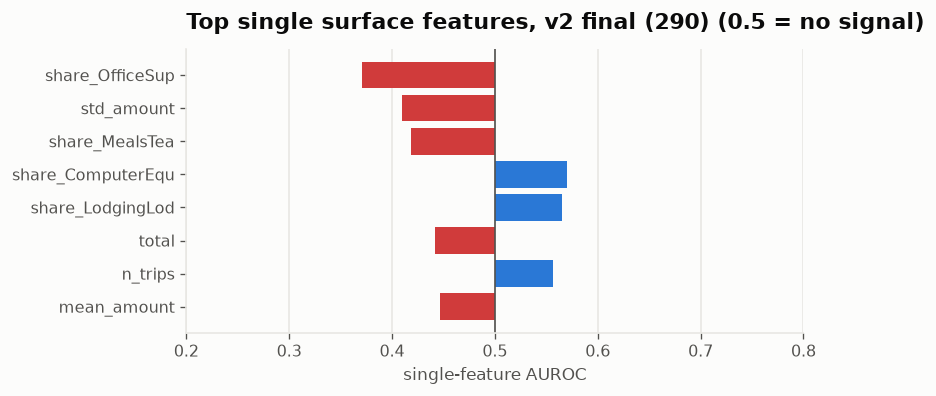

In [8]:
key=[k for k in G if k.startswith("v2 final")][0]; uni=G[key][2] and G[key][1][:8]
fig,ax=plt.subplots(figsize=(7,3.4)); nm=[u[1] for u in uni][::-1]; au=[u[2] for u in uni][::-1]
ax.barh(nm,[a-.5 for a in au],left=.5,color=[PAL["crit"] if a<.5 else PAL["ft"] for a in au]); ax.axvline(.5,color=PAL["ink2"],lw=1); ax.set_xlim(.2,.8); ax.grid(axis="y",visible=False); ax.grid(axis="x")
ax.set_title(f"Top single surface features, {key} (0.5 = no signal)"); ax.set_xlabel("single-feature AUROC"); dz.finish(fig)
dz.callout("bad","The gate still <b>fails</b> for v2 final: a few surface features (category mix, amount spread) still carry signal. v2 is much better than v1, but not clean. Validation numbers must be read with that in mind.")

In [9]:
dz.banner(4, 'Training runs', 'Three arms: one local, two on rented GPUs')

In [10]:
ARMS=[dict(name="Mac mini, Qwen3-4B",kind="MLX LoRA",data="110 histories",log=RES/"mini_v2.log",ev=RES/"mini_v2_eval.json",col=PAL["haiku"]),
      dict(name="Modal, Qwen3.5-9B",kind="QLoRA 4-bit, A100-80GB",data="290 histories",log=V2/"modal_9b.log",ev=RES/"modal_Qwen3.5-9B_eval.json",col=PAL["ft"]),
      dict(name="Modal, Qwen3.5-27B",kind="QLoRA 4-bit, A100-80GB",data="290 histories",log=V2/"modal_27b.log",ev=RES/"modal_Qwen3.5-27B_eval.json",col=PAL["ai"])]
def parse_log(p):
    tr=[];va=[]
    if not p.exists(): return tr,va
    t=p.read_text(errors="ignore")
    for m in re.finditer(r"\{[^{}]*'(loss|eval_loss)'[^{}]*\}",t):
        try: d=eval(m.group(0),{"__builtins__":{}},{})
        except Exception: continue
        ep=float(d["epoch"]) if "epoch" in d else None
        if "eval_loss" in d: va.append((ep,float(d["eval_loss"])))
        elif "loss" in d: tr.append((ep,float(d["loss"])))
    for m in re.finditer(r"Iter (\d+): Train loss ([\d.]+)",t): tr.append((int(m.group(1)),float(m.group(2))))
    for m in re.finditer(r"Iter (\d+): Val loss ([\d.]+)",t): va.append((int(m.group(1)),float(m.group(2))))
    return tr,va
def load_eval(p):
    if not p.exists(): return None
    try:
        d=json.load(open(p)); a=lambda s:tuple(int(x) for x in str(s).split("/"))
        return dict(rec=a(d["history_recall"]),fa=a(d["clean_false_alarms"]),raw=d)
    except Exception as e: print("bad eval json",p.name,e); return None
for a in ARMS:
    a["loss"]=parse_log(a["log"]); a["res"]=load_eval(a["ev"])
rows=[]
for a in ARMS:
    r=a["res"]; tr,va=a["loss"]
    rows.append((a["name"],a["kind"],a["data"],"done" if r else "pending",f"{len(tr)} / {len(va)}",f"{tr[-1][1]:.3f}" if tr else "-",f"{va[-1][1]:.3f}" if va else "-",
                 f"{r['rec'][0]}/{r['rec'][1]}" if r else "-",f"{r['fa'][0]}/{r['fa'][1]}" if r else "-"))
display(pd.DataFrame(rows,columns=["arm","method","data","status","train/val log points","last train loss","last val loss","history recall","clean false alarms"]).set_index("arm"))
dz.cards([(("DONE" if a["res"] else "PENDING"),a["name"],(a["kind"]+" on "+a["data"]+(". Evaluation file found." if a["res"] else ". Waiting for "+a["ev"].name+"; this card fills automatically when it appears.")),PAL["good"] if a["res"] else PAL["muted"]) for a in ARMS])

,method,data,status,train/val log points,last train loss,last val loss,history recall,clean false alarms
arm,,,,,,,,
"Mac mini, Qwen3-4B",MLX LoRA,110 histories,pending,0 / 0,-,-,-,-
"Modal, Qwen3.5-9B","QLoRA 4-bit, A100-80GB",290 histories,pending,6 / 1,0.484,0.497,-,-
"Modal, Qwen3.5-27B","QLoRA 4-bit, A100-80GB",290 histories,pending,1 / 0,1.604,-,-,-


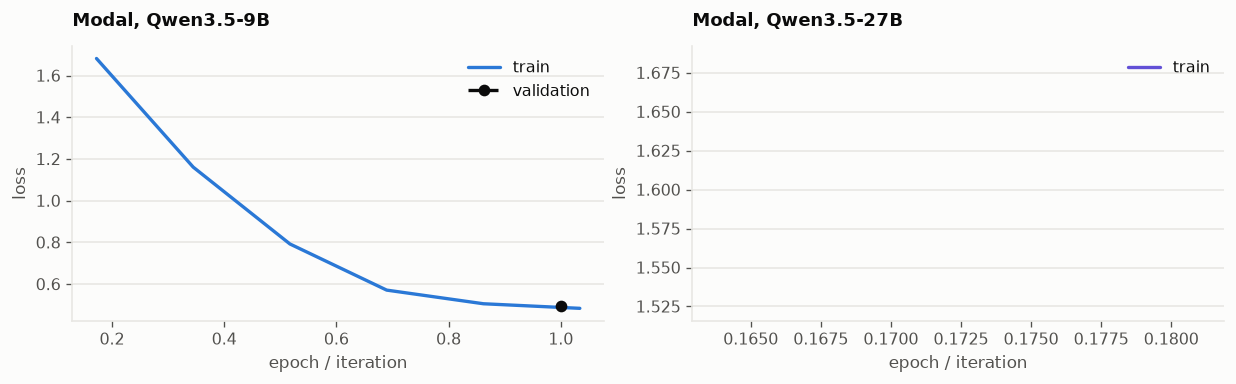

In [11]:
have=[a for a in ARMS if a["loss"][0] or a["loss"][1]]
if not have: print("No training logs yet.")
else:
    fig,axs=plt.subplots(1,len(have),figsize=(5.2*len(have),3.3),squeeze=False)
    for ax,a in zip(axs[0],have):
        tr,va=a["loss"]
        if tr: ax.plot([x[0] if x[0] is not None else i for i,x in enumerate(tr)],[x[1] for x in tr],color=a["col"],label="train")
        if va: ax.plot([x[0] if x[0] is not None else i for i,x in enumerate(va)],[x[1] for x in va],"o--",color=PAL["ink"],label="validation")
        ax.set_title(a["name"],fontsize=11); ax.set_xlabel("epoch / iteration"); ax.set_ylabel("loss"); ax.legend()
    dz.finish(fig)
    dz.callout("learned","Loss curves are parsed from the run logs on disk. A logged run that was cut short shows only the part that was recorded; the arm stays <b>pending</b> until its evaluation JSON exists.")

In [12]:
dz.banner(5, 'Comparison panel', 'Recall and false alarms with 95% Wilson intervals')

In [13]:
def ci(k,n): return ev.wilson(k,n)
done=[a for a in ARMS if a["res"]]
if not done:
    dz.callout("warn","No v2 evaluation files yet. The panel below fills in automatically once <code>modal_Qwen3.5-9B_eval.json</code> / <code>modal_Qwen3.5-27B_eval.json</code> (and the mini arm) exist in <code>v2/results</code>.",title="Pending")
else:
    fig,axs=plt.subplots(1,2,figsize=(11,3.4))
    for ax,(lab,field) in zip(axs,[("History recall (fraud histories flagged)","rec"),("False alarms (clean histories escalated)","fa")]):
        for i,a in enumerate(done):
            k,n=a["res"][field]; lo,hi=ci(k,n); p=100*k/n
            ax.errorbar(p,i,xerr=[[p-lo],[hi-p]],fmt="o",color=a["col"],capsize=4,ms=8); ax.text(hi+2,i,f"{k}/{n} = {p:.0f}%  [{lo}-{hi}]",va="center",fontsize=9)
        ax.set_yticks(range(len(done))); ax.set_yticklabels([a["name"] for a in done]); ax.set_xlim(0,150); ax.set_xticks([0,25,50,75,100]); ax.grid(axis="y",visible=False); ax.grid(axis="x"); ax.set_title(lab,fontsize=11); ax.set_xlabel("%")
    dz.finish(fig)
dz.callout("warn","<b>Exam v2-valid:</b> the held-out schemes and held-out clean histories of <code>v2/sft/valid.jsonl</code> (58 histories). Same pool of authors as training, different schemes.",title="What is measured above")

### Reference only: the v1 exam (E5), a DIFFERENT exam
The numbers below come from the **v1 exam E5**: a different set of histories, a different construction and a different scoring set. They are **not comparable** with the v2-valid results above, and no ranking should be drawn from putting them side by side. They are shown only so nobody confuses the two.

In [14]:
E5=[("v1 tuned Qwen3-4B (E5)","80% recall","97% false alarms",PAL["ft"]),("Sonnet agents (E5)","79-88% recall","0% false alarms",PAL["sonnet"]),("Opus 4.5 API (E5)","46% recall","3% false alarms",PAL["opus"])]
dz.cards([("E5, NOT COMPARABLE",n,f"{r}<br>{f}",PAL["muted"]) for n,r,f,c in E5])
dz.callout("bad","The v1 tuned model reached 80% recall but with 97% false alarms: it flagged almost everything, which is what the anti-shortcut gate and the clean-history balance in v2 were built to expose. Do not read E5 and v2-valid on one axis.",title="Not comparable")

In [15]:
dz.banner(6, 'Limits and what is not claimed', 'What would a careful reviewer object to?')

In [16]:
dz.cards([("Not claimed","No independent exam (E6)","The independent exam E6 has not been run or scored here. Nothing in this notebook is evidence of generalisation to unseen authors or real fraud.",PAL["crit"]),
("Caveat","Held-out schemes, same authors","Validation holds out whole schemes, but the authors (Claude, DeepSeek, Kimi) are the same families as in training. Style leakage across the split is possible.",PAL["warn"]),
("Caveat","Gate still above 0.60","Surface features still predict the label better than the target allows (section 3). Part of any score may be shortcut.",PAL["warn"]),
("Caveat","4-bit QLoRA","Large arms are trained and evaluated in 4-bit; results may differ in higher precision.",PAL["muted"]),
("Caveat","Single seed, small n","One run per arm, 58 validation histories. Wilson intervals are wide; small differences are noise.",PAL["muted"]),
("Safety","The engine keeps the verdict","Whatever the model does, it can only escalate pass -> review. A false alarm costs reviewer time, not a wrong rejection.",PAL["good"])])

In [17]:
dz.banner(7, 'How to reproduce', 'Commands, in order (run from finetune/v2)')

```bash
cd finetune/v2
python gen.py            # skeletons + multi-family generation, engine-validated histories -> out/*.json
python claude_route.py   # Claude-agent route for the histories written by Claude agents
python build_sft_v2.py   # gate report, scheme-level split -> sft/train.jsonl, valid.jsonl, split.json
modal run modal_train.py                          # Qwen3.5-9B QLoRA on A100-80GB
modal run modal_train.py --base Qwen/Qwen3.5-27B  # 27B arm
python -c "import gate"  # gate.report(texts, labels) recomputes the AUROC
```
The Mac mini arm (Qwen3-4B, MLX LoRA) writes its log to `v2/results/mini_v2.log`. Evaluation JSONs go to `v2/results/` and this notebook picks them up on the next run. No API keys are needed to run this notebook.